# Lista 1 – Regressão Linear Múltipla

- **Exercício 1:** modelo de regressão múltipla para predizer as vendas (`Propagandas.csv`).
- **Exercício 2:** três modelos de regressão múltipla para predizer o preço dos automóveis (`Preços_Carros.csv`).

### Preparação do ambiente

In [1]:
# Importação das bibliotecas necessárias
import numpy as np # Para operações numéricas
import pandas as pd # Para manipulação de dados em DataFrame
import matplotlib.pyplot as plt # Para criação de gráficos
import seaborn as sns # Para visualização de dados estatísticos

sns.set_theme(style='whitegrid')

## Exercício 1 – Propagandas

Objetivo: predizer `Vendas` a partir do investimento em `TV`, `Radio` e `Jornal`.

### 1 – Análise descritiva

Carregando a base de dados

In [2]:
propagandas = pd.read_csv('../data/Propagandas.csv')

Visualização das 5 primeiras linhas

In [3]:
propagandas.head()

,TV,Radio,Jornal,Vendas
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


Dimensão da base de dados e tipo das variáveis

In [4]:
print(f"Observações: {propagandas.shape[0]} | Variáveis: {propagandas.shape[1]}")
propagandas.dtypes

Observações: 200 | Variáveis: 4


TV        float64
Radio     float64
Jornal    float64
Vendas    float64
dtype: object

Verificação de valores ausentes e linhas duplicadas

In [5]:
print(f"Linhas duplicadas: {propagandas.duplicated().sum()}")
propagandas.isnull().sum()

Linhas duplicadas: 0


TV        0
Radio     0
Jornal    0
Vendas    0
dtype: int64

A base possui 200 observações e 4 variáveis, todas numéricas (`float64`), sem valores ausentes e sem linhas duplicadas. Não é necessário nenhum tratamento inicial.

#### Medidas de tendência central, dispersão e forma

Além do `describe()`, calculamos o coeficiente de variação (CV), que permite comparar a dispersão de variáveis com médias diferentes, e a assimetria.

In [ ]:
resumo = propagandas.describe().T
resumo['CV (%)'] = propagandas.std() / propagandas.mean() * 100
resumo['assimetria'] = propagandas.skew()
resumo.round(2)

- **TV:** média (147,04) e mediana (149,75) próximas e assimetria quase nula (-0,07). É a variável com os maiores valores, chegando a 296,4.
- **Radio:** média (23,26) e mediana (22,90) próximas, distribuição praticamente simétrica (0,09). O mínimo é 0, ou seja, há observação sem investimento em rádio.
- **Jornal:** média (30,55) acima da mediana (25,75) e assimetria positiva (0,90): a maioria dos investimentos é baixa, com alguns valores bem altos. Tem o maior CV (71,28%).
- **Vendas:** assimetria positiva leve (0,41), média (14,02) um pouco acima da mediana (12,90). É a variável menos dispersa em termos relativos (CV de 37,21%).

#### Distribuição das variáveis

Histogramas (forma da distribuição) e boxplots (dispersão e possíveis outliers) de cada variável.

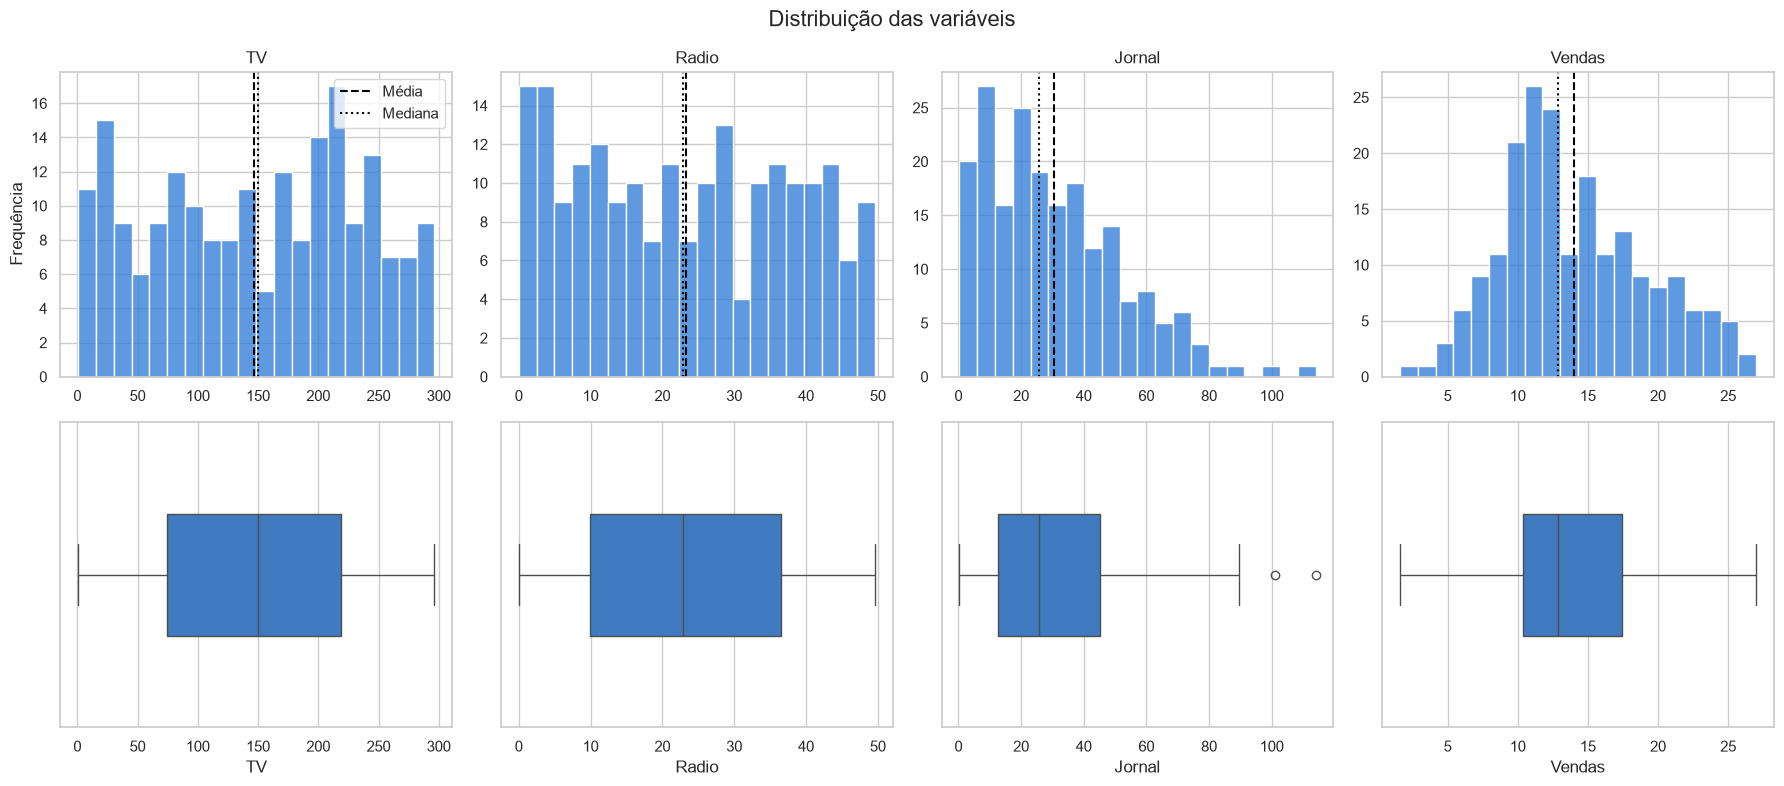

In [7]:
cor = '#2a78d6'
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i, coluna in enumerate(propagandas.columns):
    # Histograma com as linhas de média e mediana
    sns.histplot(propagandas[coluna], bins=20, color=cor, ax=axes[0, i])
    axes[0, i].axvline(propagandas[coluna].mean(), color='black', linestyle='--', label='Média')
    axes[0, i].axvline(propagandas[coluna].median(), color='black', linestyle=':', label='Mediana')
    axes[0, i].set_title(coluna)
    axes[0, i].set_xlabel('')
    axes[0, i].set_ylabel('Frequência' if i == 0 else '')

    # Boxplot
    sns.boxplot(x=propagandas[coluna], color=cor, width=0.4, ax=axes[1, i])

axes[0, 0].legend()
fig.suptitle('Distribuição das variáveis', fontsize=16)
plt.tight_layout()
plt.show()

#### Contagem de outliers pelo IQR

Critério visto em aula: são considerados outliers os valores abaixo de Q1 - 1,5·IQR ou acima de Q3 + 1,5·IQR.

In [8]:
Q1 = propagandas.quantile(0.25)
Q3 = propagandas.quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR
mascara_outliers = (propagandas < limite_inferior) | (propagandas > limite_superior)

print("Outliers por variável:")
print(mascara_outliers.sum())

# Observações com pelo menos um outlier
propagandas[mascara_outliers.any(axis=1)]

Outliers por variável:
TV        0
Radio     0
Jornal    2
Vendas    0
dtype: int64


,TV,Radio,Jornal,Vendas
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


Apenas `Jornal` apresenta outliers: duas observações (114,0 e 100,9), acima do limite superior de 93,63. Os valores são plausíveis para um investimento em propaganda e não há indício de erro de digitação, então as observações foram **mantidas**. A influência delas no modelo será verificada na análise de resíduos.

#### Relação entre as variáveis

O pairplot mostra a distribuição de cada variável na diagonal e a dispersão entre cada par fora dela.

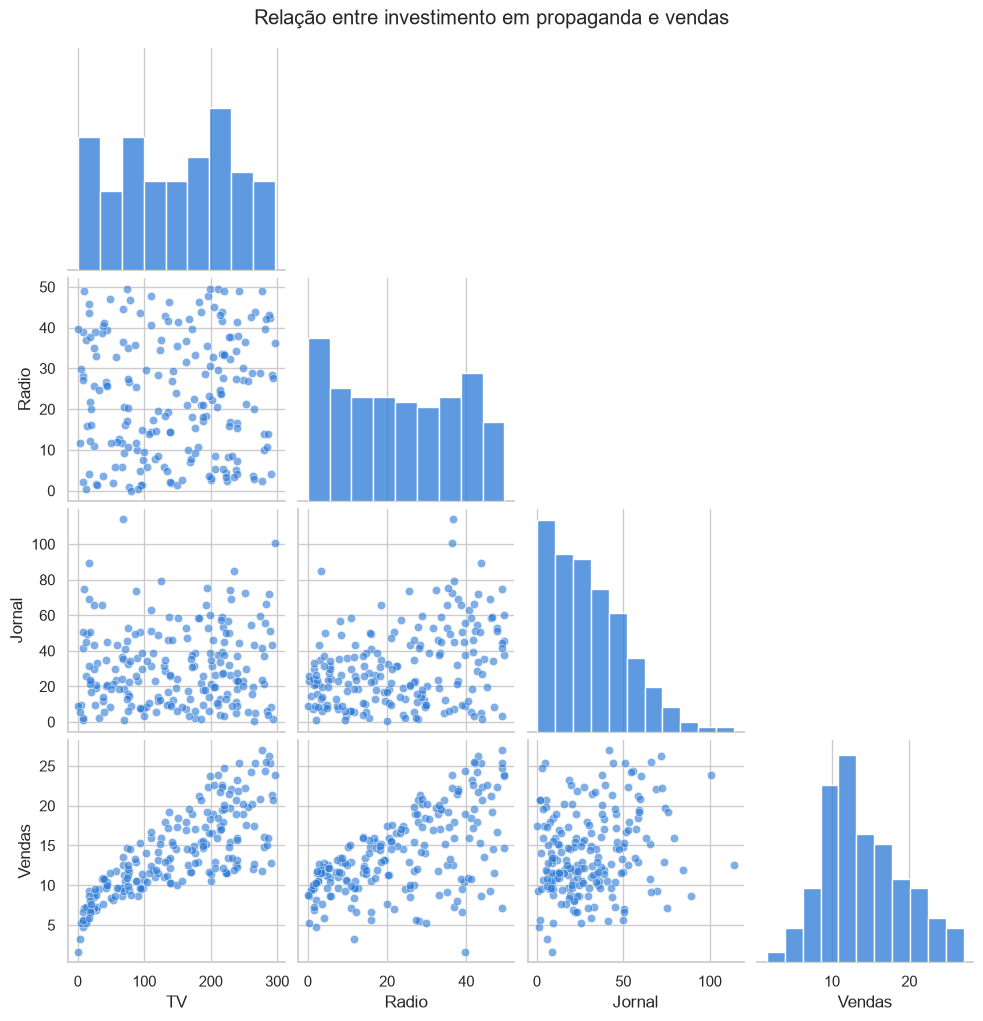

In [9]:
grafico = sns.pairplot(propagandas, corner=True, plot_kws={'color': cor, 'alpha': 0.6}, diag_kws={'color': cor})
grafico.figure.suptitle('Relação entre investimento em propaganda e vendas', y=1.02)
plt.show()

#### Conclusão da análise descritiva

- A base está completa e não precisou de tratamento.
- `Vendas` cresce junto com `TV`, a relação visualmente mais clara das três. A dispersão das vendas também aumenta conforme o investimento em TV cresce, um possível sinal de heterocedasticidade a ser testado nos resíduos.
- `Radio` também tem relação positiva com `Vendas`, porém com mais dispersão.
- `Jornal` tem a relação mais fraca com `Vendas` e é a única variável com outliers (2 observações).
- Entre as preditoras não se observa relação linear forte, o que será verificado na correlação e no VIF.